In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

# Find project root
current_dir = Path.cwd().resolve()

ROOT_DIR = next(
    (
        p for p in [current_dir, *current_dir.parents]
        if (p / "config.py").exists()
    ),
    None
)

if ROOT_DIR is None:
    raise FileNotFoundError("Project root not found!")

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from config import METADATA_FILE, DATASET_DIR

# Load metadata
metadata = pd.read_csv(METADATA_FILE)

# Select the first ECG record
sample = metadata.iloc[0]

record_path = DATASET_DIR / sample["filename_lr"]

# Load 12-lead ECG signal
signal, info = wfdb.rdsamp(str(record_path))

print("ECG ID:", sample["ecg_id"])
print("Patient ID:", sample["patient_id"])
print("Fold:", sample["strat_fold"])
print("Signal shape:", signal.shape)
print("Sampling rate:", info["fs"], "Hz")
print("Lead names:", info["sig_name"])
print("Duration:", signal.shape[0] / info["fs"], "seconds")
print("Missing/invalid values:", np.size(signal) - np.isfinite(signal).sum())

assert signal.shape == (1000, 12)
assert info["fs"] == 100

print("\nECG loaded successfully!")

ECG ID: 1
Patient ID: 15709.0
Fold: 3
Signal shape: (1000, 12)
Sampling rate: 100 Hz
Lead names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
Duration: 10.0 seconds
Missing/invalid values: 0

ECG loaded successfully!


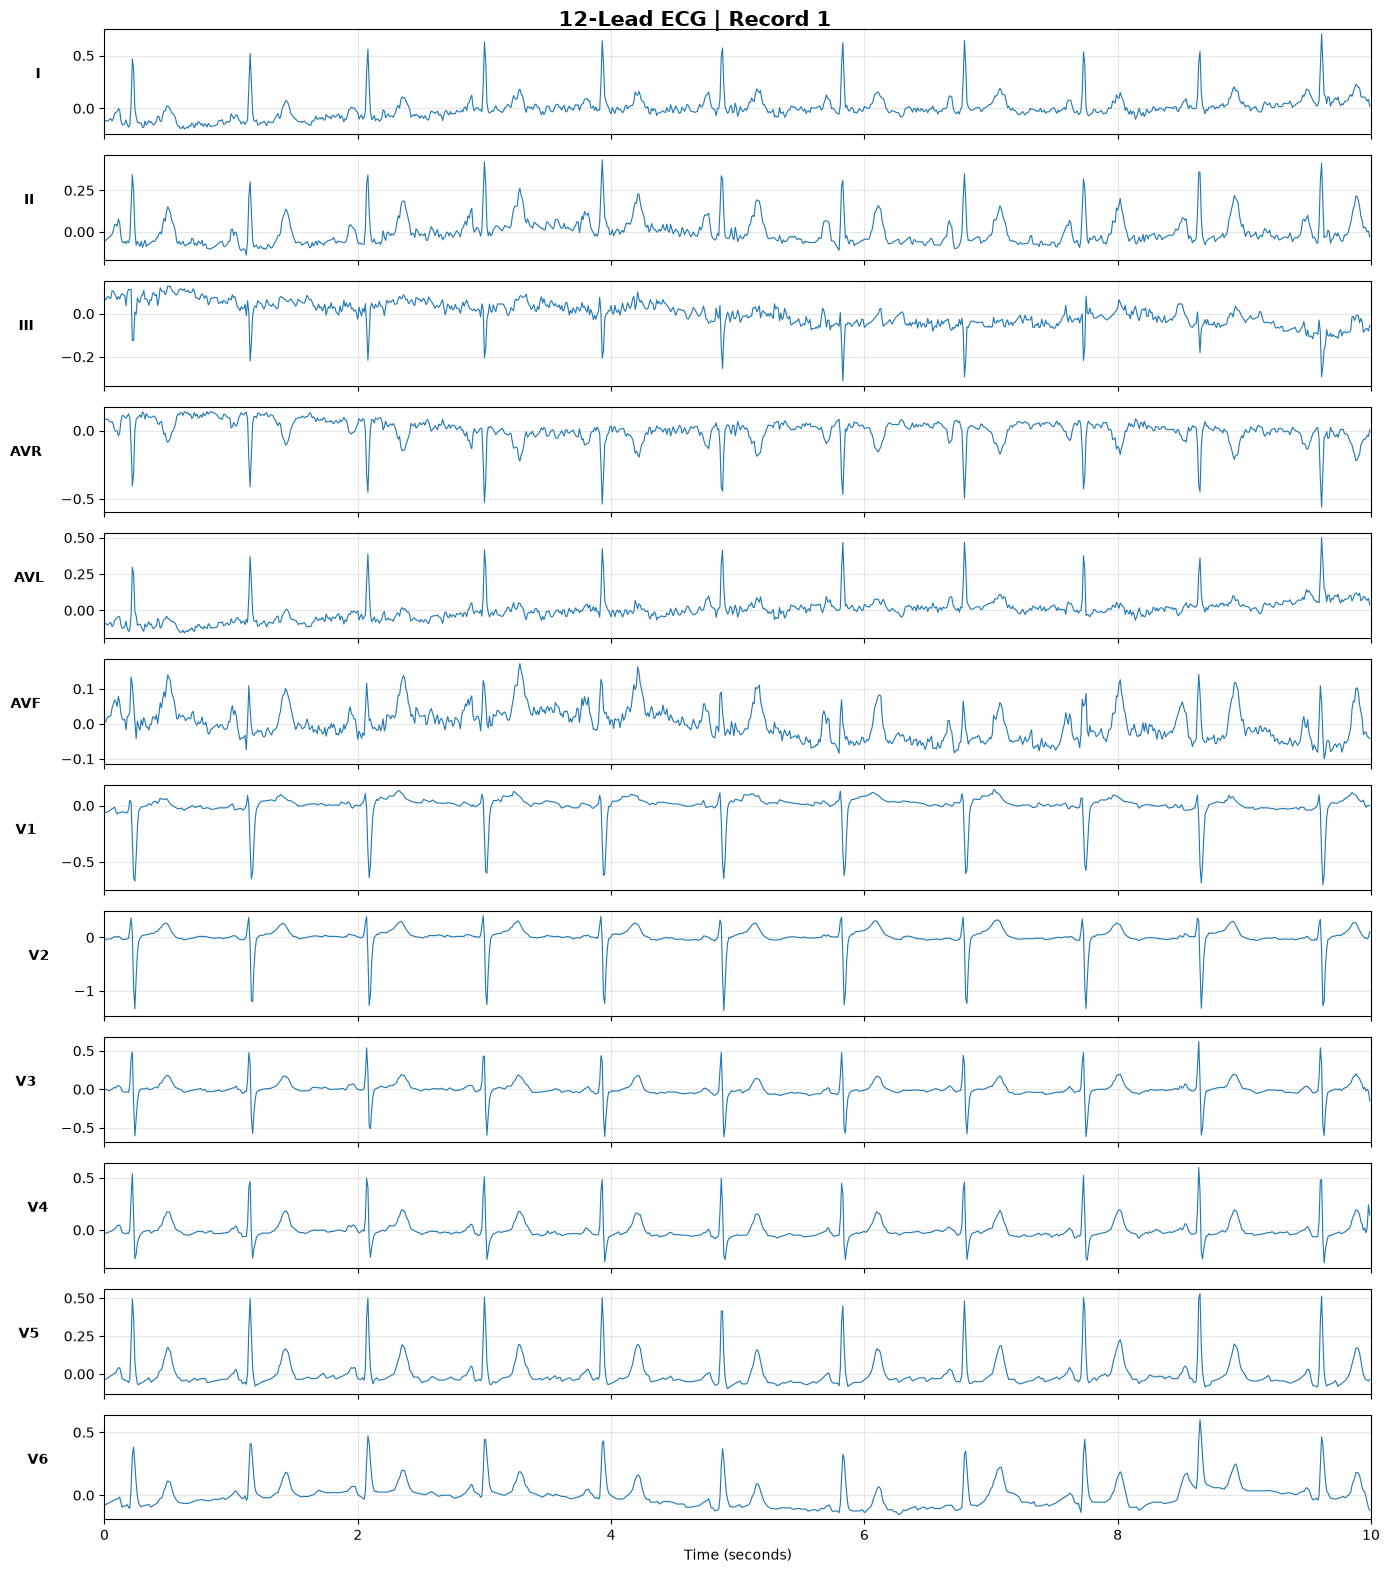

In [ ]:
# Time axis in seconds
time = np.arange(signal.shape[0]) / info["fs"]

lead_names = info["sig_name"]

fig, axes = plt.subplots(
    12, 1,
    figsize=(14, 16),
    sharex=True
)

for i, ax in enumerate(axes):

    ax.plot(
        time,
        signal[:, i],
        linewidth=0.8
    )

    ax.set_ylabel(
        lead_names[i],
        rotation=0,
        labelpad=25,
        fontsize=10,
        fontweight="bold"
    )

    ax.grid(True, alpha=0.3)
    ax.set_xlim(0, 10)

axes[-1].set_xlabel("Time (seconds)")

fig.suptitle(
    f"12-Lead ECG | Record {sample['ecg_id']}",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
import ast
import pandas as pd

from config import SCP_FILE

# Load diagnostic code definitions
scp_df = pd.read_csv(SCP_FILE, index_col=0)

print("Metadata shape:", metadata.shape)
print("SCP statements shape:", scp_df.shape)

print("\nSCP columns:")
print(scp_df.columns.tolist())

# Parse string dictionaries safely
metadata["scp_codes_parsed"] = (
    metadata["scp_codes"].apply(ast.literal_eval)
)

# Inspect first ECG labels
first_codes = metadata.iloc[0]["scp_codes_parsed"]

print("\nFirst ECG codes:")
print(first_codes)

# Show descriptions of the first ECG codes
print("\nCode descriptions:")
print(
    scp_df.loc[
        [code for code in first_codes if code in scp_df.index],
        ["description", "diagnostic", "diagnostic_class"]
    ].to_string()
)

# Inspect available diagnostic classes
print("\nDiagnostic classes:")
print(
    scp_df["diagnostic_class"]
    .dropna()
    .value_counts()
)

Metadata shape: (21799, 28)
SCP statements shape: (71, 12)

SCP columns:
['description', 'diagnostic', 'form', 'rhythm', 'diagnostic_class', 'diagnostic_subclass', 'Statement Category', 'SCP-ECG Statement Description', 'AHA code', 'aECG REFID', 'CDISC Code', 'DICOM Code']

First ECG codes:
{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}

Code descriptions:
                                                description  diagnostic diagnostic_class
NORM                                             normal ECG         1.0             NORM
LVOLT  low QRS voltages in the frontal and horizontal leads         NaN              NaN
SR                                             sinus rhythm         NaN              NaN

Diagnostic classes:
diagnostic_class
MI      14
STTC    13
CD      11
HYP      5
NORM     1
Name: count, dtype: int64


In [ ]:
import pandas as pd

# Five diagnostic superclasses
CLASS_NAMES = ["NORM", "MI", "STTC", "CD", "HYP"]

# Map diagnostic SCP codes to their superclasses
diagnostic_map = (
    scp_df.loc[
        scp_df["diagnostic"] == 1.0,
        "diagnostic_class"
    ]
    .dropna()
    .to_dict()
)

print("Number of diagnostic SCP codes:", len(diagnostic_map))

# Convert SCP codes to diagnostic classes
def extract_diagnostic_classes(scp_codes):
    classes = {
        diagnostic_map[code]
        for code in scp_codes
        if code in diagnostic_map
    }
    return sorted(classes)


# Create a separate DataFrame for labels
labels_df = metadata[
    ["ecg_id", "patient_id", "strat_fold", "scp_codes_parsed"]
].copy()

labels_df["diagnostic_classes"] = (
    labels_df["scp_codes_parsed"]
    .apply(extract_diagnostic_classes)
)

# Convert diagnostic classes to binary targets
for class_name in CLASS_NAMES:
    labels_df[class_name] = (
        labels_df["diagnostic_classes"]
        .apply(lambda classes: int(class_name in classes))
    )

# Number of active labels per ECG
labels_df["num_labels"] = (
    labels_df[CLASS_NAMES].sum(axis=1)
)

print("\nFirst 5 ECG labels:")
print(
    labels_df[
        ["ecg_id", "diagnostic_classes"] + CLASS_NAMES
    ].head().to_string(index=False)
)

print("\nECG count per diagnostic class:")
print(labels_df[CLASS_NAMES].sum())

print("\nNumber of diagnostic labels per ECG:")
print(
    labels_df["num_labels"]
    .value_counts()
    .sort_index()
)

print("\nECGs without diagnostic labels:",
      (labels_df["num_labels"] == 0).sum())

print("ECGs with multiple diagnostic labels:",
      (labels_df["num_labels"] > 1).sum())

Number of diagnostic SCP codes: 44

First 5 ECG labels:
 ecg_id diagnostic_classes  NORM  MI  STTC  CD  HYP
      1             [NORM]     1   0     0   0    0
      2             [NORM]     1   0     0   0    0
      3             [NORM]     1   0     0   0    0
      4             [NORM]     1   0     0   0    0
      5             [NORM]     1   0     0   0    0

ECG count per diagnostic class:
NORM    9514
MI      5469
STTC    5235
CD      4898
HYP     2649
dtype: int64

Number of diagnostic labels per ECG:
num_labels
0      411
1    16244
2     4068
3      919
4      157
Name: count, dtype: int64

ECGs without diagnostic labels: 411
ECGs with multiple diagnostic labels: 5144


Total ECGs: 21799
ECGs included: 21388
ECGs excluded: 411

Class Distribution:
      count  prevalence_pct
NORM   9514           44.48
MI     5469           25.57
STTC   5235           24.48
CD     4898           22.90
HYP    2649           12.39

Max/Min Class Ratio: 3.59


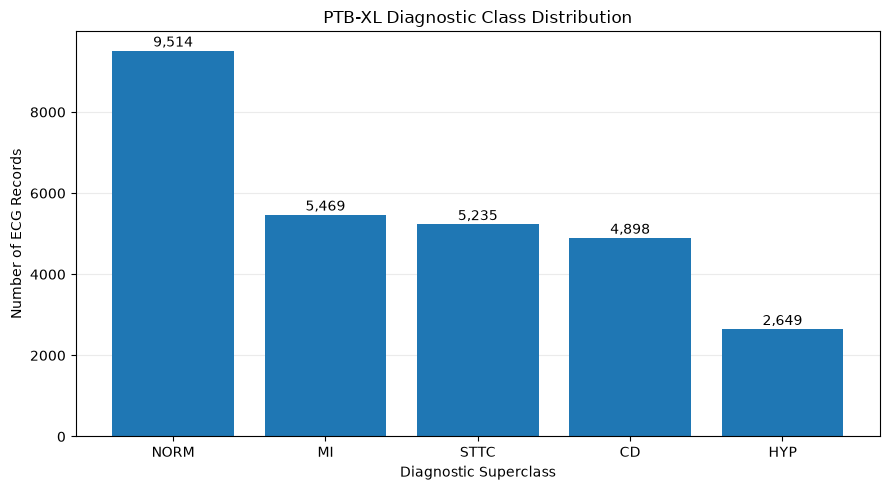


Class distribution figure saved!


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

from config import PLOTS_DIR

# Keep the original labels_df unchanged
model_df = labels_df[
    labels_df["num_labels"] > 0
].copy().reset_index(drop=True)

print("Total ECGs:", len(labels_df))
print("ECGs included:", len(model_df))
print("ECGs excluded:", len(labels_df) - len(model_df))

# Class distribution
class_counts = model_df[CLASS_NAMES].sum()

class_prevalence = (
    class_counts / len(model_df) * 100
)

distribution_df = pd.DataFrame({
    "count": class_counts,
    "prevalence_pct": class_prevalence
})

print("\nClass Distribution:")
print(distribution_df.round(2))

# Class imbalance ratio
imbalance_ratio = (
    class_counts.max() / class_counts.min()
)

print(
    f"\nMax/Min Class Ratio: {imbalance_ratio:.2f}"
)

# Plot
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    distribution_df.index,
    distribution_df["count"]
)

ax.set_title("PTB-XL Diagnostic Class Distribution")
ax.set_xlabel("Diagnostic Superclass")
ax.set_ylabel("Number of ECG Records")

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 100,
        f"{int(height):,}",
        ha="center"
    )

plt.tight_layout()

# Save figure
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    PLOTS_DIR / "class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nClass distribution figure saved!")

In [ ]:
import pandas as pd

from config import DATA_DIR

# Work on a copy
split_df = model_df.copy()

# Official PTB-XL fold assignment
fold_mapping = {
    **{i: "train" for i in range(1, 9)},
    9: "val",
    10: "test"
}

# Validate metadata before splitting
assert split_df["ecg_id"].is_unique, "Duplicate ECG IDs!"
assert split_df["patient_id"].notna().all(), "Missing patient IDs!"
assert split_df["strat_fold"].isin(fold_mapping).all(), "Invalid folds!"

# Assign each ECG to its official split
split_df["split"] = (
    split_df["strat_fold"].map(fold_mapping)
)

# Attach relative ECG record paths
split_df = split_df.merge(
    metadata[["ecg_id", "filename_lr"]],
    on="ecg_id",
    how="left",
    validate="one_to_one"
)

assert split_df["filename_lr"].notna().all()

# Check patient independence
patient_split_counts = (
    split_df.groupby("patient_id")["split"]
    .nunique()
)

overlapping_patients = (
    patient_split_counts > 1
).sum()

print("Total ECGs:", len(split_df))
print("Patients appearing in multiple splits:",
      overlapping_patients)

assert overlapping_patients == 0, (
    "Patient leakage detected!"
)

# Split summary
summary = (
    split_df.groupby("split")
    .agg(
        ecg_count=("ecg_id", "count"),
        patient_count=("patient_id", "nunique")
    )
    .reindex(["train", "val", "test"])
)

print("\nDataset Split Summary:")
print(summary)

# Diagnostic labels in each split
print("\nClass Distribution by Split:")

class_distribution = (
    split_df.groupby("split")[CLASS_NAMES]
    .sum()
    .reindex(["train", "val", "test"])
)

print(class_distribution)

# Verify all five classes are represented
assert (class_distribution > 0).all().all(), (
    "A diagnostic class is missing in a split!"
)

# Prepare dataset index for future DataLoaders
columns_to_save = [
    "ecg_id",
    "patient_id",
    "strat_fold",
    "split",
    "filename_lr",
] + CLASS_NAMES

output_df = split_df[columns_to_save].copy()

# Save reproducible dataset splits
DATA_DIR.mkdir(parents=True, exist_ok=True)

output_path = DATA_DIR / "splits.csv"

output_df.to_csv(output_path, index=False)

print("\nPatient-independent split verified!")
print("Saved to:", output_path)

Total ECGs: 21388
Patients appearing in multiple splits: 0

Dataset Split Summary:
       ecg_count  patient_count
split                          
train      17084          14823
val         2146           1917
test        2158           1877

Class Distribution by Split:
       NORM    MI  STTC    CD   HYP
split                              
train  7596  4379  4186  3907  2119
val     955   540   528   495   268
test    963   550   521   496   262

Patient-independent split verified!
Saved to: D:\projects\vscode\ECG-Classification\data\splits.csv
